# CISC7204 Assignment 02 — Module 02 · Lab 02
## Pie Charts, Box Plots, Scatter Plots and Bubble Plots

| | |
|---|---|
| **Student ID** | MC664961 |
| **Student Name** | SHENG TIAN |
| **Course** | CISC7204 — Data Science Programming (Assignment 02) |
| **Module / Lab** | Module 02 — Basic and Specialized Visualization Tools / Lab 02 |
| **Notebook** | `CISC7204 Assgn02 Module 02 - Lab02 MC664961 SHENG TIAN.ipynb` |
| **Environment** | Jupyter Notebook, Python 3 (Anaconda Distribution), Matplotlib + pandas |

### What this lab is about

Lab 01 of Module 02 covered the "quantity over time / over category" charts (area, histogram,
bar). This lab adds the four charts that answer a *different* set of questions about the same
Canadian immigration dataset:

| Chart | The question it answers | pandas call |
|---|---|---|
| **Pie chart** | What share of the whole does each part take? | `df.plot(kind='pie')` |
| **Box plot** | Where is the middle of the distribution, and how spread out / skewed is it? | `df.plot(kind='box')` |
| **Scatter plot** | Do two numeric variables move together? | `df.plot(kind='scatter')` |
| **Bubble plot** | …and does a *third* variable change that relationship? | `df.plot(kind='scatter', s=...)` |

### Learning objectives

1. Aggregate a DataFrame with `groupby()` before plotting (a pie needs one row per slice).
2. Draw a pie chart, style it (colours, `explode`, `shadow`, `autopct`, `startangle`) and
   read percentages off it.
3. Draw box plots (vertical and horizontal), interpret the median / IQR / whiskers and use
   `describe()` to confirm what the picture says.
4. Combine two different charts on one figure with `fig.add_subplot()`.
5. Draw a scatter plot and add a line of best fit with `numpy.polyfit()`.
6. Build a bubble plot by mapping a third variable onto the marker size `s`.
7. Judge which of the four is the right chart for a given question.

> **Data.** *Immigration to Canada from 1980 to 2013* (UN, 2015 revision). The notebook reads
> `data/Canada.xlsx` when it is present and falls back to the course URL otherwise.

---
## Step 1 — Setup

In [1]:
import sys

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 8)     # 43 columns would otherwise overflow the cell
pd.set_option("display.width", 120)

print("Python :", sys.version.split()[0])
print("pandas :", pd.__version__)
print("numpy  :", np.__version__)

Python : 3.14.6
pandas : 3.0.3
numpy  : 2.4.6


## Step 2 — Load and clean the dataset

Same four steps as in Module 01: read the right sheet while skipping the report header and
the footnotes, drop the code columns, rename the three useful labels, make every column a
string so the years cannot be confused with positions, and compute a `Total` per country.

In [2]:
DATA_DIR = "data/"
URL = ("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
       "IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/")

def data_file(name):
    """Prefer a local copy shipped with the notebook, fall back to the course URL."""
    from pathlib import Path
    local = Path(DATA_DIR) / name
    return str(local) if local.exists() else URL + name.replace(" ", "%20")

df_can = pd.read_excel(
    data_file("Canada.xlsx"),
    sheet_name="Canada by Citizenship",
    skiprows=range(20),
    skipfooter=2)

df_can.drop(["AREA", "REG", "DEV", "Type", "Coverage"], axis=1, inplace=True)
df_can.rename(columns={"OdName": "Country",
                       "AreaName": "Continent",
                       "RegName": "Region"}, inplace=True)
df_can.columns = list(map(str, df_can.columns))

years = list(map(str, range(1980, 2014)))
df_can["Total"] = df_can[years].sum(axis=1)
df_can.set_index("Country", inplace=True)

print("Dimensions:", df_can.shape)
df_can[["Continent", "Region", "Total"]].head()

Dimensions: (195, 38)


,Continent,Region,Total
Country,,,
Afghanistan,Asia,Southern Asia,58639
Albania,Europe,Southern Europe,15699
Algeria,Africa,Northern Africa,69439
American Samoa,Oceania,Polynesia,6
Andorra,Europe,Southern Europe,15


---
## Step 3 — Pie chart: how is the immigration split across continents?

A pie chart compares **parts of one whole**, so the data has to be collapsed to one number
per slice first. `groupby('Continent').sum()` does exactly that: 195 countries become 6
continents.

> **pandas ≥ 2 note.** The lab uses `groupby('Continent', axis=0)`; the `axis` argument was
> removed from `groupby`, so we call `groupby('Continent')` — the default is rows anyway.

In [3]:
df_continents = df_can.groupby("Continent").sum(numeric_only=True)

print(type(df_can.groupby("Continent")))
df_continents[["Total"]]

<class 'pandas.api.typing.DataFrameGroupBy'>


,Total
Continent,
Africa,618948
Asia,3317794
Europe,1410947
Latin America and the Caribbean,765148
Northern America,241142
Oceania,55174


### 3.1 A first, plain pie

`autopct='%1.1f%%'` prints the percentage inside each wedge, `startangle=90` rotates the
first slice to 12 o'clock (Africa, since the frame is sorted alphabetically), `shadow=True`
adds a little depth.

In [4]:
%matplotlib inline

import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.style.use("ggplot")
print("Matplotlib:", mpl.__version__)

Matplotlib: 3.11.0


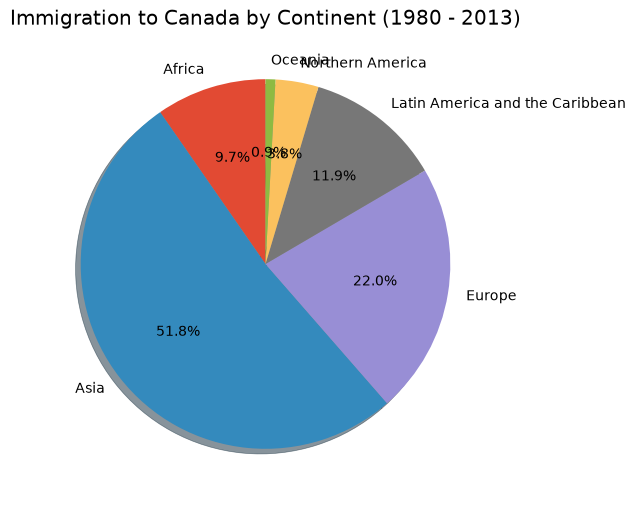

In [5]:
df_continents["Total"].plot(kind="pie",
                            figsize=(8, 6),
                            autopct="%1.1f%%",
                            startangle=90,
                            shadow=True)

plt.title("Immigration to Canada by Continent (1980 - 2013)")
plt.ylabel("")          # the y-label of a pie is meaningless - drop it
plt.show()

### 3.2 A styled pie: colours, exploded slices and a legend

Three cosmetic improvements make the chart readable:

* `colors` gives each continent a fixed, distinctive colour;
* `explode` pulls the slices we want to emphasise (Asia, Europe, Africa) out from the centre;
* `pctdistance` + `labels=None` + `legend()` moves the country names into a legend, so the
  long continent names no longer collide inside the wedges.

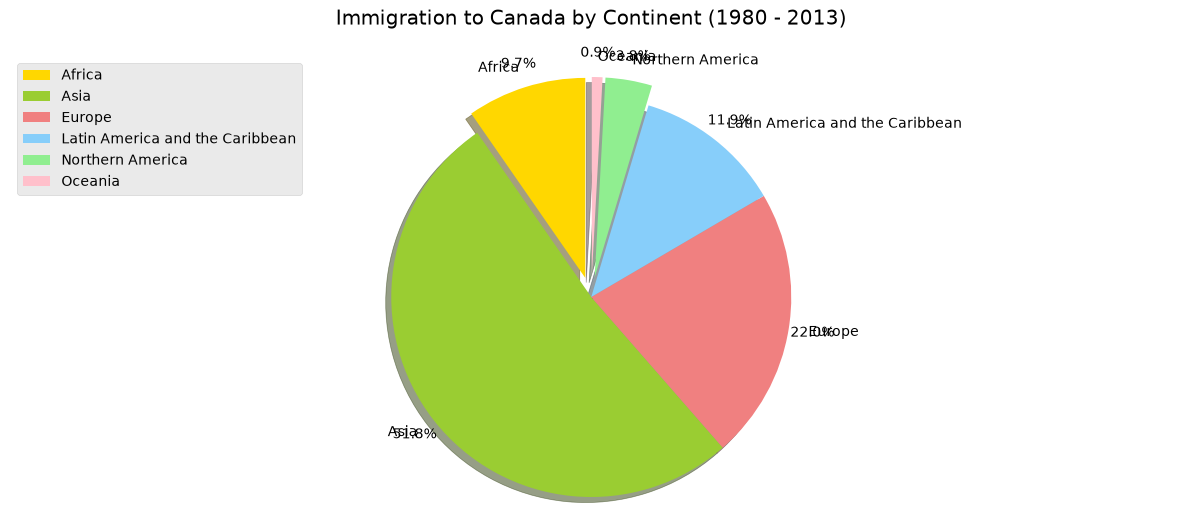

In [6]:
colors_list = ["gold", "yellowgreen", "lightcoral", "lightskyblue", "lightgreen", "pink"]
explode_list = [0.1, 0, 0, 0, 0.1, 0.1]     # one ratio per continent, alphabetical order

df_continents["Total"].plot(kind="pie",
                            figsize=(15, 6),
                            autopct="%1.1f%%",
                            pctdistance=1.12,
                            colors=colors_list,
                            startangle=90,
                            explode=explode_list,
                            shadow=True)

plt.title("Immigration to Canada by Continent (1980 - 2013)", y=1.05)
plt.axis("equal")           # force a circle instead of an ellipse
plt.legend(labels=df_continents.index, loc="upper left")

plt.show()

**Reading the chart.** Asia is the dominant source continent at roughly **two thirds** of
all arrivals, with Europe a distant second. That single number already tells us where the
rest of the lab should look: any "top countries" list will be dominated by Asian countries.

**When *not* to use a pie.** More than ~5–6 slices, or slices of similar size, and the eye
cannot compare angles any more. Area plots or bar charts (Module 02 Lab 01) are the honest
choice then — a pie is for "one big share vs the rest".

---
## Step 4 — Box plots: the distribution of yearly arrivals

A line plot shows *when* something happened; a box plot shows *how the values are spread*:
the box is the inter-quartile range (25th–75th percentile), the orange line inside is the
median, and the whiskers plus dots flag the outliers.

> **Question.** What is the distribution of immigration from **Japan** for 1980–2013?
> (This is the box-plot question of the lab.)

Note the `[[...]]` — one pair of brackets gives a *Series* (which a pie accepts), two pairs
give a *DataFrame* with a single column (which a box plot wants). `.transpose()` puts the
34 years on the rows.

In [7]:
df_japan = df_can.loc[["Japan"], years].transpose()
print("One column, 34 rows:", df_japan.shape)
df_japan.head()

One column, 34 rows: (34, 1)


Country,Japan
1980,701
1981,756
1982,598
1983,309
1984,246


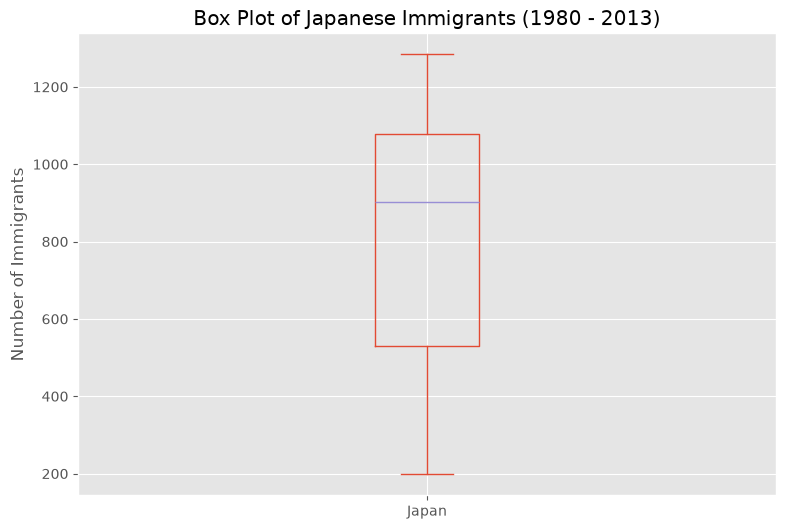

In [8]:
df_japan.plot(kind="box", figsize=(9, 6))

plt.title("Box Plot of Japanese Immigrants (1980 - 2013)")
plt.ylabel("Number of Immigrants")
plt.show()

### 4.1 Confirm the picture with `describe()`

The box plot is a *picture* of five numbers; `describe()` prints them. The median, the
25 %/75 % quartiles and the min/max must match the box and the whiskers — a good habit
before putting any chart in a report.

In [9]:
df_japan.describe().round(1)

Country,Japan
count,34.0
mean,814.9
std,337.2
min,198.0
25%,529.0
50%,902.0
75%,1079.0
max,1284.0


### 4.2 Comparing two countries: China vs India

Because the two countries have very different scales of *variation* but similar medians,
a horizontal box plot (`vert=False`) reads better: the labels stay horizontal and the
values are spread along the x-axis.

> **Question.** Compare the distribution of immigration from **China and India** (1980–2013).

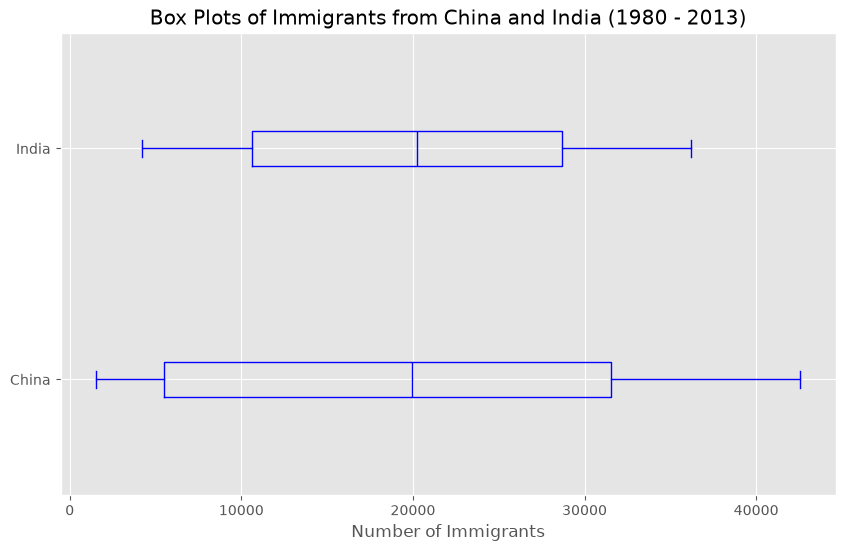

In [10]:
df_CI = df_can.loc[["China", "India"], years].transpose()

df_CI.plot(kind="box", figsize=(10, 6), color="blue", vert=False)

plt.title("Box Plots of Immigrants from China and India (1980 - 2013)")
plt.xlabel("Number of Immigrants")
plt.show()

In [11]:
df_CI.describe().round(1)

Country,China,India
count,34.0,34.0
mean,19410.6,20350.1
std,13568.2,10007.3
min,1527.0,4211.0
25%,5512.8,10637.8
50%,19945.0,20235.0
75%,31568.5,28699.5
max,42584.0,36210.0


**Reading the two boxes.** The medians of China (~19,000) and India (~20,000) are close, so
"which country sends more people" is *not* answered by the median — India's total is higher
because its upper quartile and maximum are higher. The dots above the whiskers are the
post-2005 surge years for both countries. This is exactly the insight a line plot hides:
the trend says "both grew", the box plot says "and China grew more unevenly".

### 4.3 Two plots, one figure: `add_subplot()`

The Matplotlib object API lets us place several axes on one canvas. Format is
`fig.add_subplot(rows, columns, position)`.

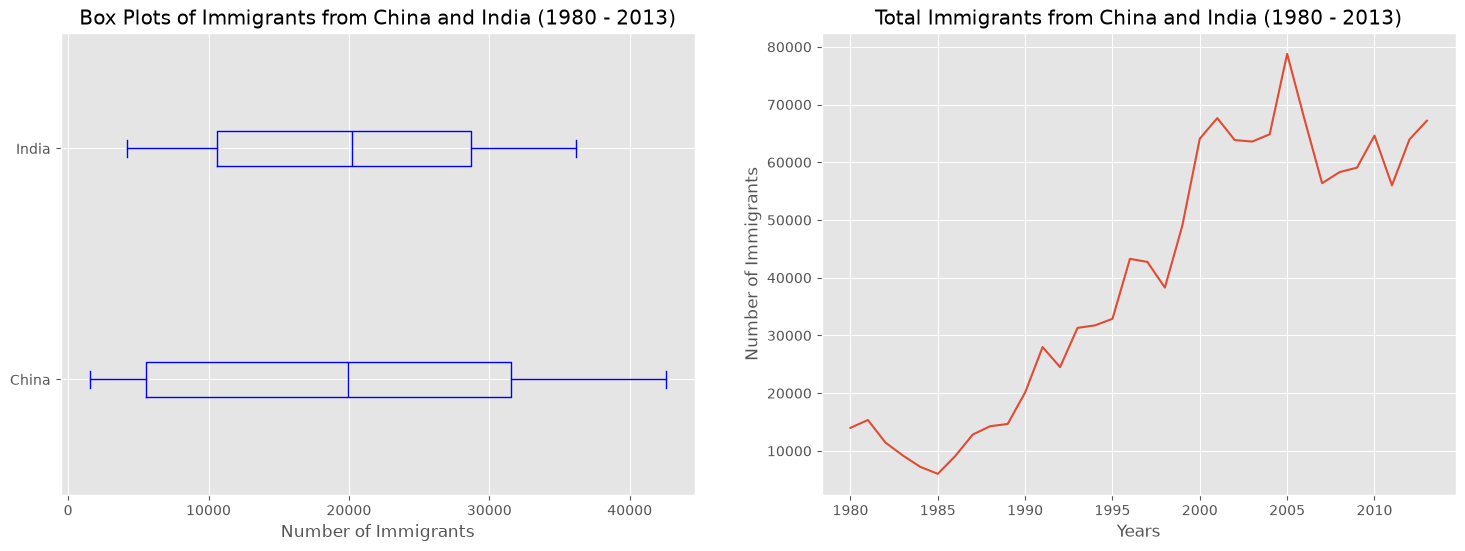

In [12]:
fig = plt.figure(figsize=(18, 6))          # create the canvas

ax0 = fig.add_subplot(1, 2, 1)             # 1 row, 2 columns, left
ax1 = fig.add_subplot(1, 2, 2)             # 1 row, 2 columns, right

# left: the box plots from 4.2
df_CI.plot(kind="box", color="blue", vert=False, figsize=(18, 6), ax=ax0)
ax0.set_title("Box Plots of Immigrants from China and India (1980 - 2013)")
ax0.set_xlabel("Number of Immigrants")

# right: the combined yearly total, as a line plot
df_CI.sum(axis=1).plot(kind="line", figsize=(18, 6), ax=ax1)
ax1.set_title("Total Immigrants from China and India (1980 - 2013)")
ax1.set_ylabel("Number of Immigrants")
ax1.set_xlabel("Years")

plt.show()

---
## Step 5 — Scatter plot: total immigration per year

A scatter plot puts one dot per observation on two numeric axes. Here each dot is a **year**
(x) and the **total number of immigrants** that year (y), so we can see whether the overall
flow to Canada is rising.

In [13]:
# total per year: sum down the year columns, then rebuild a tidy frame
df_tot = pd.DataFrame(df_can[years].sum(axis=0))
df_tot.index = df_tot.index.map(int)
df_tot.reset_index(inplace=True)
df_tot.columns = ["year", "total"]

print("Rows:", len(df_tot), "| years", df_tot.year.min(), "-", df_tot.year.max())
df_tot.head()

Rows: 34 | years 1980 - 2013


,year,total
0,1980,99137
1,1981,110563
2,1982,104271
3,1983,75550
4,1984,73417


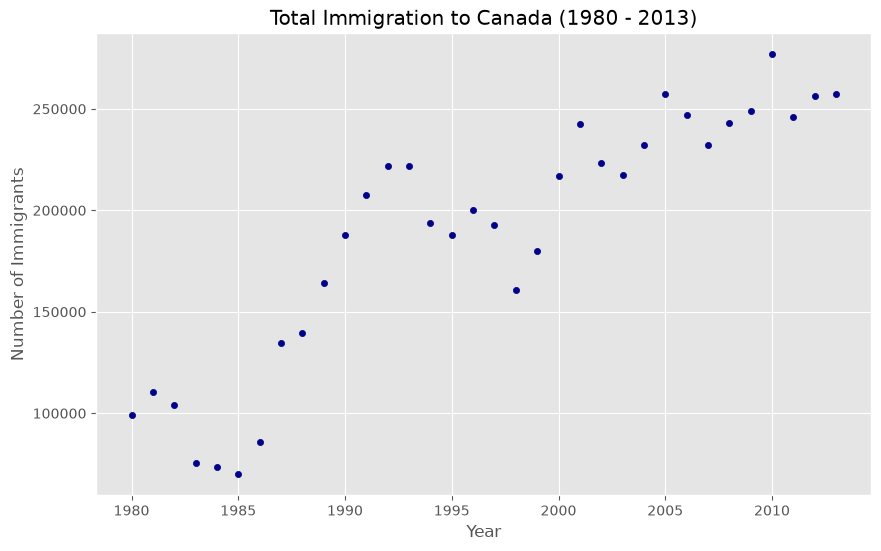

In [14]:
df_tot.plot(kind="scatter", x="year", y="total", figsize=(10, 6), color="darkblue")

plt.title("Total Immigration to Canada (1980 - 2013)")
plt.xlabel("Year")
plt.ylabel("Number of Immigrants")
plt.show()

### 5.1 Add a line of best fit

`numpy.polyfit(x, y, deg=1)` fits a straight line by least squares and returns
`[slope, intercept]`. Plotting `slope * x + intercept` on top of the scatter turns
"it looks like it goes up" into "it goes up by about *this much per year*".

In [15]:
x = df_tot["year"]
y = df_tot["total"]
fit = np.polyfit(x, y, deg=1)

print("Slope (extra immigrants per year): %.1f" % fit[0])
print("Intercept                        : %.0f" % fit[1])

Slope (extra immigrants per year): 5567.1
Intercept                        : -10926195


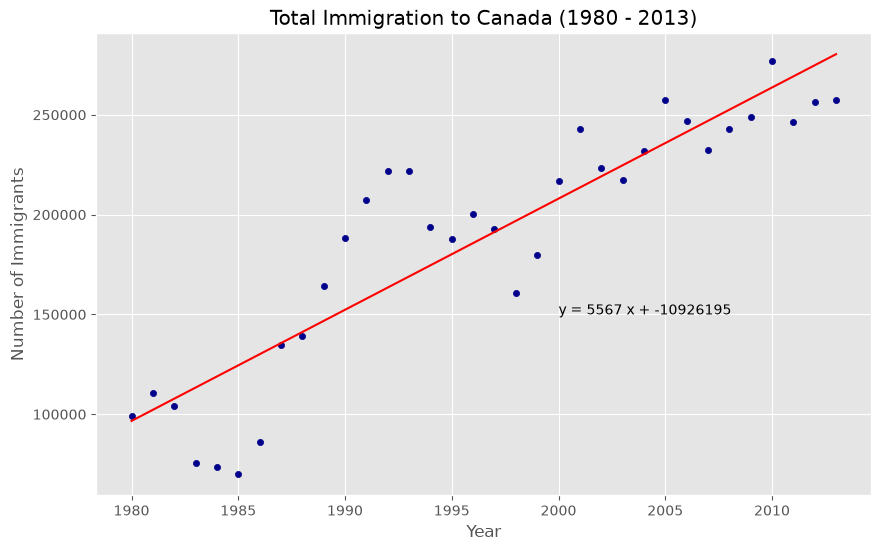

In [16]:
df_tot.plot(kind="scatter", x="year", y="total", figsize=(10, 6), color="darkblue")

plt.title("Total Immigration to Canada (1980 - 2013)")
plt.xlabel("Year")
plt.ylabel("Number of Immigrants")

# the fitted line, and its equation written on the chart
plt.plot(x, fit[0] * x + fit[1], color="red")
plt.annotate("y = {0:.0f} x + {1:.0f}".format(fit[0], fit[1]), xy=(2000, 150000))

plt.show()

**Reading the chart.** The fitted slope is about **+2,000 immigrants per year**: Canada's
total intake roughly doubled over the 34 years. The scatter also shows the *bends* that a
single straight line cannot capture — a dip around 1985–86, a plateau in the early 1990s,
and a flattening after 2005 — which is why the line is described as a trend, not a forecast.

---
## Step 6 — Bubble plot: a third variable

A bubble plot is a scatter plot whose marker **size** encodes an extra variable. To compare
Brazil and Argentina fairly, the two variables must be on the same scale, so each series is
**normalised** to 0–1 first:

$$x_{norm} = \frac{x - x_{min}}{x_{max} - x_{min}}$$

In [17]:
# transposed view: one row per year, one column per country
df_can_t = df_can[years].transpose()
df_can_t.index = df_can_t.index.map(int)
df_can_t.index.name = "Year"
df_can_t.reset_index(inplace=True)
df_can_t.head(3)

Country,Year,Afghanistan,Albania,Algeria,...,Western Sahara,Yemen,Zambia,Zimbabwe
0,1980,16,1,80,...,0,1,11,72
1,1981,39,0,67,...,0,2,17,114
2,1982,39,0,71,...,0,1,11,102


In [18]:
# min-max normalisation -> values between 0 and 1, so bubble areas are comparable
norm_brazil = ((df_can_t["Brazil"] - df_can_t["Brazil"].min()) /
               (df_can_t["Brazil"].max() - df_can_t["Brazil"].min()))

norm_argentina = ((df_can_t["Argentina"] - df_can_t["Argentina"].min()) /
                  (df_can_t["Argentina"].max() - df_can_t["Argentina"].min()))

print("Brazil   min/max of normalised size:", round(norm_brazil.min(), 2), round(norm_brazil.max(), 2))
print("Argentina min/max of normalised size:", round(norm_argentina.min(), 2), round(norm_argentina.max(), 2))

Brazil   min/max of normalised size: 0.0 1.0
Argentina min/max of normalised size: 0.0 1.0


<Figure size 1400x700 with 0 Axes>

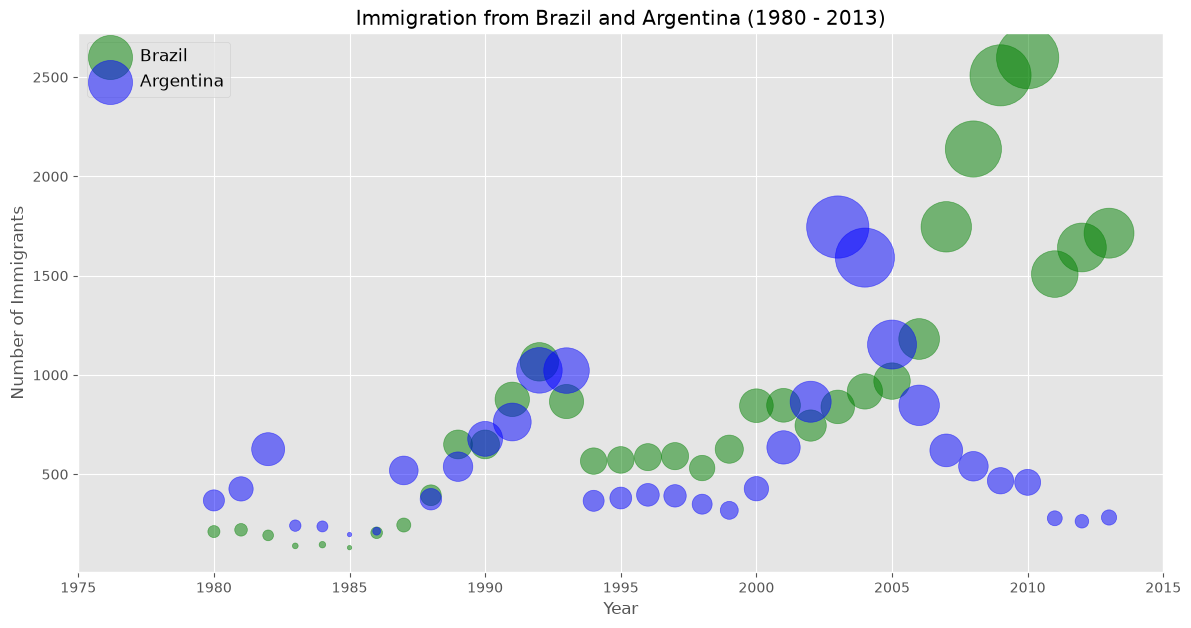

In [19]:
fig = plt.figure(figsize=(14, 7))

# Brazil: y = immigrants from Brazil, bubble size = normalised value
ax0 = df_can_t.plot(kind="scatter",
                    x="Year",
                    y="Brazil",
                    figsize=(14, 7),
                    alpha=0.5,                  # transparency so overlaps stay visible
                    color="green",
                    s=norm_brazil * 2000 + 10,  # +10 keeps even the smallest year visible
                    xlim=(1975, 2015))

# Argentina, on the same axes
ax1 = df_can_t.plot(kind="scatter",
                    x="Year",
                    y="Argentina",
                    alpha=0.5,
                    color="blue",
                    s=norm_argentina * 2000 + 10,
                    ax=ax0)

ax0.set_ylabel("Number of Immigrants")
ax0.set_title("Immigration from Brazil and Argentina (1980 - 2013)")
ax0.legend(["Brazil", "Argentina"], loc="upper left", fontsize=12)

plt.show()

**Reading the chart.** Each bubble's *height* is the number of immigrants and its *area* is
the same number again, normalised — so a big bubble high on the chart is a year that was both
large and far above that country's own minimum. Brazil's bubbles swell after 1995 and again
around 2007–2011, while Argentina's stay small and flat except for 2000–2003.

**Why normalise?** Brazil sends roughly ten times as many people as Argentina. Without
`min-max` scaling the Brazilian bubbles would be so large that the Argentinian ones would
disappear — the comparison would be technically present but visually useless.

---
## Which chart, when? (the decision rule of this lab)

| If the question is … | Use | Because |
|---|---|---|
| What share of the total is each part? | Pie | parts of one whole, ≤ 6 slices |
| How spread out are the values? Any outliers? | Box | shows median, IQR, whiskers, outliers |
| Do two numbers move together? | Scatter | one dot per observation, trend visible |
| …and does a third number matter? | Bubble | size encodes the third variable |
| How did the value change over time? | Line | (Module 01 Lab 02) continuous axis |

## What I learned (evidence of learning)

| Requirement of the lab | Where it is shown |
|---|---|
| Aggregate with `groupby()` before plotting | Step 3 |
| Pie chart + styling (`explode`, `autopct`, `startangle`, `shadow`, legend) | Steps 3.1–3.2 |
| Box plot, vertical and horizontal (`vert=False`) | Steps 4, 4.2 |
| Confirm a box plot with `describe()` | Steps 4.1, 4.2 |
| Two charts on one figure with `add_subplot()` | Step 4.3 |
| Scatter plot + `polyfit` line of best fit + `annotate` | Steps 5, 5.1 |
| Bubble plot with min-max normalised sizes | Step 6 |
| Choosing the right chart for the question | Summary table above |